# TrustRAG: results and demo

Adhithyan (230121003), Aditya Raj (230121004)

TrustRAG finds sentences in a RAG answer that the source passages don't support. This notebook shows our results and then runs the system live.

Run it from the `notebooks` folder, top to bottom. Part 1 only reads the saved files in `results/`, so it takes seconds and needs no GPU. Part 2 runs the models. The first time that downloads about 5 GB, and it is a lot faster with a GPU.

In [1]:
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)
pd.set_option("display.max_colwidth", None)


def load(*parts):
    with open(os.path.join(ROOT, "results", *parts), encoding="utf-8") as f:
        return json.load(f)


qa, small, summary = load("qa", "metrics.json"), load("qa_base", "metrics.json"), load("summary", "metrics.json")

# Part 1: results

## Data

RAGTruth QA, split by source passage so no passage appears in two splits. A sentence counts as unsupported if an annotated span covers at least three of its characters.

In [2]:
pd.DataFrame([{"Split": name, "Answers": s["answers"], "Sentences": s["claims"], "Passages": s["passages"],
               "Unsupported": f"{s['unsupported'] / s['claims']:.1%}"}
              for name, s in (("Train", qa["sizes"]["fit"]), ("Calibration", qa["sizes"]["val"]), ("Test", qa["sizes"]["test"]))])

,Split,Answers,Sentences,Passages,Unsupported
0,Train,4284,31507,714,9.7%
1,Calibration,750,5445,125,9.8%
2,Test,900,5790,150,6.2%


## Detection

AUROC of 0.5 is random. The chance level for AUPRC is the share of unsupported sentences, 6.2% here. NLI alone doesn't beat word overlap, and the six features from our proposal only tie it. Adding six more features is what moves the score.

,Method,AUROC,AUPRC
0,Random,0.475,0.057
1,Word overlap,0.757,0.120
2,Embedding similarity,0.688,0.091
3,"NLI, whole passage",0.727,0.123
4,"NLI, best sentence",0.725,0.119
5,TrustRAG v1 (6 features),0.760,0.156
6,TrustRAG v2 (12 features),0.833,0.320
7,"TrustRAG v2, boosted trees",0.883,0.423


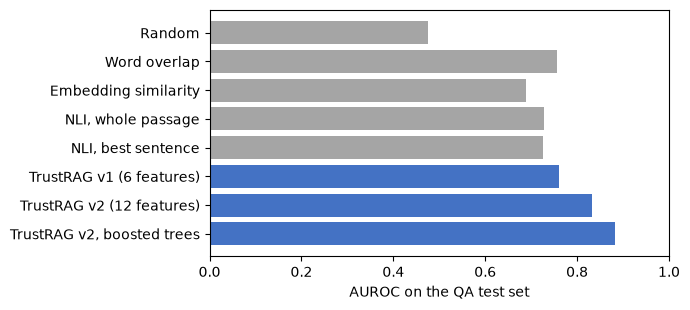

In [3]:
detection = pd.DataFrame(qa["baselines"])[["name", "auroc", "auprc"]].round(3)
detection.columns = ["Method", "AUROC", "AUPRC"]
display(detection)

fig, ax = plt.subplots(figsize=(7, 3.2))
colours = ["#4472C4" if n.startswith("TrustRAG") else "#A5A5A5" for n in detection["Method"]]
ax.barh(detection["Method"][::-1], detection["AUROC"][::-1], color=colours[::-1])
ax.set_xlim(0, 1)
ax.set_xlabel("AUROC on the QA test set")
plt.tight_layout()
plt.show()

## Which features matter

We removed groups of features and retrained. Word matching carries most of the signal inside RAGTruth.

In [4]:
features = pd.DataFrame(qa["ablation"])[["model", "cv_auroc", "auroc"]].round(3)
features.columns = ["Logistic regression on", "CV AUROC", "Test AUROC"]
features

,Logistic regression on,CV AUROC,Test AUROC
0,All 12 features,0.835,0.833
1,Without the lexical features (v1),0.780,0.760
2,Without the NLI features,0.822,0.822
3,Without embedding similarity,0.835,0.832
4,Without position and answer length,0.822,0.812
5,Lexical features only,0.781,0.803
6,NLI features only,0.728,0.733


## Calibration and actions

Raw probabilities are far too high because of the balanced class weights. Isotonic regression fixes that, which lets us act on each sentence: show it, flag it or hold it back.

,Method,ECE,Brier
0,Raw,0.287,0.167
1,Platt,0.033,0.051
2,Isotonic,0.033,0.052


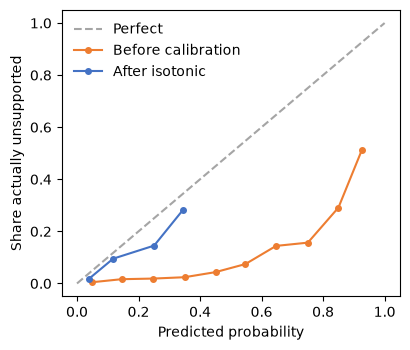

Flag threshold 0.15, hold threshold 0.50


,Action,Share of sentences,Unsupported among them
0,Show,83.2%,3.0%
1,Flag,16.3%,20.6%
2,Hold,0.4%,79.2%


In [5]:
cal = qa["calibration"]
display(pd.DataFrame([{"Method": name, "ECE": round(cal[k]["ece"], 3), "Brier": round(cal[k]["brier"], 3)}
                      for name, k in (("Raw", "raw"), ("Platt", "platt"), ("Isotonic", "isotonic"))]))

fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.plot([0, 1], [0, 1], "--", color="#A5A5A5", label="Perfect")
for key, label, colour in (("raw", "Before calibration", "#ED7D31"), ("isotonic", "After isotonic", "#4472C4")):
    pts = [p for p in qa["reliability"][key] if p[2] >= 20]
    ax.plot([p[0] for p in pts], [p[1] for p in pts], "o-", color=colour, label=label, markersize=4)
ax.set_xlabel("Predicted probability")
ax.set_ylabel("Share actually unsupported")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

sel = qa["selective"]
print(f"Flag threshold {sel['t_flag']:.2f}, hold threshold {sel['t_hold']:.2f}")
pd.DataFrame([{"Action": a.capitalize(), "Share of sentences": f"{sel['actions'][a]['share']:.1%}",
               "Unsupported among them": f"{sel['actions'][a]['unsupported_rate']:.1%}"} for a in ("show", "flag", "hold")])

## Where it fails

Added information is caught well. Contradictions are the weak spot, because they reuse the passage's words and the word features treat them as safe. Refusals also cause false alarms, since they share almost no words with the passages.

In [6]:
types = pd.DataFrame([t for t in qa["per_type"] if t["n"]])[["type", "n", "auroc", "auroc_nli_only"]].round(3)
types.columns = ["Error type", "Sentences", "TrustRAG v2", "NLI only"]
types

,Error type,Sentences,TrustRAG v2,NLI only
0,Evident Baseless Info,273,0.850,0.727
1,Subtle Baseless Info,55,0.871,0.731
2,Evident Conflict,32,0.623,0.693


## Verifier size

The smaller verifier loses little once the word features are added, and it runs about twice as fast.

In [7]:
def row(name, params, m):
    best = {b["name"]: b["auroc"] for b in m["baselines"]}["NLI, best sentence"]
    return {"Verifier": name, "Parameters": params, "NLI alone": round(best, 3), "v2": round(m["trustrag"]["auroc"], 3),
            "ms per answer": round(m["cost"]["ms_per_answer"]), "Peak GPU (GB)": round(m["cost"]["peak_gpu_mb"] / 1024, 1)}


pd.DataFrame([row("DeBERTa-v3-large", "435M", qa), row("DeBERTa-v3-base", "184M", small)])

,Verifier,Parameters,NLI alone,v2,ms per answer,Peak GPU (GB)
0,DeBERTa-v3-large,435M,0.725,0.833,544,2.6
1,DeBERTa-v3-base,184M,0.685,0.825,242,1.5


## Comparison with LLM judges

Two gpt-oss models through the Groq API, on the same sample of test sentences. The intervals overlap and every paired gap includes zero, so on this sample we can't say one method beats another.

In [8]:
boot, judges = load("judges", "bootstrap.json"), load("judges", "judges.json")
f1 = {m["name"]: m.get("f1") for m in judges["methods"]}
print(f"{boot['claims']} sentences from {boot['answers']} answers, {boot['unsupported']} unsupported")
display(pd.DataFrame([{"Method": k, "AUROC": round(m["auroc"], 3),
                       "AUROC 95% interval": f"{m['auroc_ci'][0]:.2f} to {m['auroc_ci'][1]:.2f}",
                       "AUPRC": round(m["auprc"], 3),
                       "AUPRC 95% interval": f"{m['auprc_ci'][0]:.2f} to {m['auprc_ci'][1]:.2f}"}
                      for k, m in boot["methods"].items()]))
pd.DataFrame([{"Judge minus": d["b"], "Metric": d["metric"].upper(), "Gap": round(d["diff"], 3),
               "95% interval": f"{d['ci'][0]:+.2f} to {d['ci'][1]:+.2f}", "Clear difference": d["ci_excludes_zero"]}
              for d in boot["differences"]])

1008 sentences from 165 answers, 59 unsupported


,Method,AUROC,AUROC 95% interval,AUPRC,AUPRC 95% interval
0,TrustRAG v2,0.817,0.78 to 0.86,0.232,0.14 to 0.35
1,Boosted trees,0.873,0.83 to 0.91,0.272,0.16 to 0.42
2,gpt-oss-120b,0.877,0.81 to 0.93,0.390,0.16 to 0.63
3,gpt-oss-20b,0.833,0.75 to 0.90,0.312,0.17 to 0.47


,Judge minus,Metric,Gap,95% interval,Clear difference
0,TrustRAG v2,AUROC,0.057,-0.02 to +0.13,False
1,TrustRAG v2,AUPRC,0.134,-0.06 to +0.34,False
2,Boosted trees,AUROC,0.002,-0.07 to +0.07,False
3,Boosted trees,AUPRC,0.089,-0.11 to +0.31,False
4,gpt-oss-20b,AUROC,0.041,-0.04 to +0.12,False
5,gpt-oss-20b,AUPRC,0.058,-0.10 to +0.24,False


## News summaries

RAGTruth's summary task. About half the articles don't fit the verifier's 512-token window, so we split the results by that. Whole-passage NLI is strongest when the article fits and drops when it gets cut off. TrustRAG hardly moves.

In [9]:
by_length = load("summary", "by_length.json")
groups = {g["group"]: g["auroc"] for g in by_length["groups"]}
names = list(groups["fits"])
overall = {b["name"]: b["auroc"] for b in summary["baselines"]}
pd.DataFrame([{"AUROC": n, "All": round(overall[n], 3), "Article fits": round(groups["fits"][n], 3),
               "Article cut off": round(groups["truncated"][n], 3)} for n in names])

,AUROC,All,Article fits,Article cut off
0,"NLI, whole passage",0.795,0.850,0.761
1,"NLI, best sentence",0.740,0.758,0.728
2,TrustRAG v2 (12 features),0.792,0.795,0.791
3,"TrustRAG v2, boosted trees",0.816,0.830,0.808


## HaluEval

We never trained on HaluEval. On random rows, answer length alone almost gives away the label, because correct answers are usually bare names. On rows where both answers have similar length, the NLI score is what carries over.

In [10]:
matched = {t["name"]: t["auroc"] for t in qa["transfer_matched"]}
pd.DataFrame([{"Scorer": t["name"], "Random rows": round(t["auroc"], 3), "Length-matched rows": round(matched[t["name"]], 3)}
              for t in qa["transfer"]])

,Scorer,Random rows,Length-matched rows
0,"TrustRAG v2, all features",0.762,0.752
1,TrustRAG without claim length,0.667,0.707
2,NLI support score only,0.656,0.757
3,Claim length only (artefact check),0.748,0.558


## Label check

The rules for what counts as unsupported leave room for judgement. An LLM labelled 108 test sentences under written guidelines, and we use those labels as a baseline for this section. It has not been checked against human annotators. The gap between the two AUROC columns is within noise on a sample this small.

In [11]:
agreement = load("label_check", "agreement.json")
pair = agreement["pairs"][0]
print(f"RAGTruth agrees with the baseline on {pair['agreement']:.0%} of {pair['n']} sentences, "
      f"kappa {pair['kappa']:.2f} (95% interval {pair['kappa_ci'][0]:.2f} to {pair['kappa_ci'][1]:.2f})")
scores = {(d["labels"], d["method"]): d["auroc"] for d in agreement["detector"]}
methods = list(dict.fromkeys(d["method"] for d in agreement["detector"]))
pd.DataFrame([{"Method": m, "AUROC against baseline": round(scores[("llm", m)], 3),
               "AUROC against RAGTruth": round(scores[("ragtruth", m)], 3)} for m in methods])

RAGTruth agrees with the baseline on 75% of 108 sentences, kappa 0.46 (95% interval 0.23 to 0.65)


,Method,AUROC against baseline,AUROC against RAGTruth
0,Word overlap,0.551,0.561
1,"NLI, best sentence",0.716,0.599
2,TrustRAG v1 (6 features),0.698,0.569
3,TrustRAG v2 (12 features),0.723,0.627
4,"TrustRAG v2, boosted trees",0.794,0.724


## Demo on 100 HotpotQA questions

A small RAG system: bge-small retrieval over 66,581 paragraphs and Qwen2.5-1.5B writing the answers. Retrieval decides most outcomes. TrustRAG checks grounding, not correctness, so it doesn't separate wrong answers from right ones.

In [12]:
demo = load("demo", "demo.json")
by_gold = demo["outcome_by_gold_retrieved"]
print(f"Answers: {demo['outcomes']['correct']:.0%} correct, {demo['outcomes']['wrong']:.0%} wrong, {demo['outcomes']['refused']:.0%} refused")
print(f"AUROC, wrong against correct answers: {demo['auroc_wrong_vs_correct']:.2f}")
print(f"Time per question: retrieval {demo['latency_ms']['retrieve']:.0f} ms, generation {demo['latency_ms']['generate']:.0f} ms, check {demo['latency_ms']['check']:.0f} ms")
pd.DataFrame(by_gold).T.rename_axis("Gold paragraphs retrieved")

Answers: 36% correct, 32% wrong, 32% refused
AUROC, wrong against correct answers: 0.47
Time per question: retrieval 3 ms, generation 2702 ms, check 271 ms


,correct,wrong,refused
Gold paragraphs retrieved,,,
0,0,3,2
1,8,20,24
2,28,9,6


# Part 2: live demo

From here on the models run for real. `check` splits an answer into sentences and scores each one. `p` is the estimated chance a sentence is unsupported. Green means show, yellow means flag and red means hold.

In [13]:
from transformers.utils import logging

from trustrag import features as F
from trustrag import rag
from trustrag.data import load_claims
from trustrag.detector import Detector, check

logging.disable_progress_bar()
detector = Detector()
check("This sentence loads the models.", ["This passage loads the models."], detector)
COLOURS = {"show": "#d9ead3", "flag": "#fff2cc", "hold": "#f4cccc"}


def show(rows):
    html = "".join(f'<div style="background:{COLOURS[r["action"]]};color:#000;padding:6px;margin:4px 0">'
                   f'<b>{r["action"].upper()} {r["p"]:.2f}</b> {r["claim"]}</div>' for r in rows)
    display(HTML(html))

## Made-up details get flagged

The passage says nothing about the cost or Napoleon.

In [14]:
tower = ("The Eiffel Tower is a wrought-iron lattice tower in Paris, France. It was built by Gustave Eiffel's company "
         "for the 1889 World's Fair. The tower is 330 metres tall and was the tallest structure in the world for 41 years.")
answer = "The tower was built for the 1889 World's Fair. It cost 7 million dollars and Napoleon ordered it to be painted gold."
rows, ms = check(answer, [tower], detector)
show(rows)
print(f"Checked in {ms:.0f} ms")

Checked in 186 ms


## A real answer that gets held

Answer 13564 from the RAGTruth test set, written by Llama-2 13B. The last sentence adds a meat thermometer and internal temperatures that the passage never mentions, and RAGTruth marks it as unsupported too.

In [15]:
test = load_claims("test", task_type="QA")
real = test[test["response_id"].astype(str) == "13564"].sort_values("claim_idx")
rows, ms = check(" ".join(real["claim"]), [real["context"].iloc[0]], detector)
show(rows)

## A failure: contradictions get through

Both of these are false, but they are shown. The words mostly match the passage, so the word features treat them as safe. This is the weak spot from Part 1.

In [16]:
rows, ms = check("The Eiffel Tower is in Berlin, Germany. The tower is 500 metres tall.", [tower], detector)
show(rows)

## The full pipeline on your own text

Put any text in `source` and ask about it. The text is split into chunks, the three closest to the question go to the generator, and every sentence of the answer gets checked. The generator is small, so it sometimes gets things wrong. That's what the checker is there for.

In [17]:
source = ("TrustRAG checks every sentence of an answer against its source passages. It uses DeBERTa-v3-large, a natural "
          "language inference model with 0.4B parameters, and does not fine-tune it. The model's scores are combined with "
          "six simple word-matching features in a logistic regression. Each sentence is then shown, flagged or held back.")

generator = rag.Generator()


def ask(question, text=source):
    parts = rag.chunks_of(text)
    top = rag.retrieve([question], F.embed(parts), k=min(rag.TOP_K, len(parts)))[0]
    passages = [parts[j] for j in top]
    rows, _ = check(generator(rag.prompt_for(question, passages)), passages, detector)
    print("Q:", question)
    show(rows)


ask("What model does TrustRAG use, and does it fine-tune it?")
ask("Who won the 2018 FIFA World Cup?")

Q: What model does TrustRAG use, and does it fine-tune it?


Q: Who won the 2018 FIFA World Cup?


The first answer is correct. The second question isn't in the text, so the generator refuses, which is right. The refusal still gets flagged though, the same false alarm we saw in Part 1.

In [18]:
generator.close()